# Task: Decision Trees, Bagging, Random Forest и Boosting

В этом ноутбуке вы научитесь:

- разбирать данные (таблицы, признаки, целевая переменная) перед обучением;
- создавать и обучать деревья решений;
- работать с ансамблями деревьев (Bagging, Random Forest);
- применять бустинг;
- подбирать гиперпараметры через GridSearchCV;
- анализировать влияние гиперпараметров.




## Анализ данных — с чем работаем

Перед построением моделей полезно посмотреть на данные: какие признаки есть, какой целевой признак, размер выборки и распределения.

In [ ]:
# 1) Iris — классический датасет (деревья, визуализация)
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris['target'] = iris.target
df_iris['species'] = df_iris['target'].map(lambda i: iris.target_names[i])

print("Iris: форма", df_iris.shape, "| признаки:",
      list(iris.feature_names),
      "| целевой класс: вид ириса (0/1/2)")
print("\nПервые строки:")
display(df_iris.head(8))
print("\nРаспределение классов (что предсказываем):")
print(df_iris['target'].value_counts().sort_index())
print("\nОписание признаков:")
display(df_iris[iris.feature_names].describe())

Iris: форма (150, 6) | признаки: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] | целевой класс: вид ириса (0/1/2)

Первые строки:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa



Распределение классов (что предсказываем):
target
0    50
1    50
2    50
Name: count, dtype: int64

Описание признаков:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
# 2) Make Moons — синтетические «полумесяцы» (Bagging, RF, Boosting)
import pandas as pd
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=500, noise=0.3, random_state=42)
df_moons = pd.DataFrame(X_moons, columns=['x1', 'x2'])
df_moons['target'] = y_moons

print("Make Moons: форма", df_moons.shape, "| признаки: x1, x2 | целевой класс: 0 или 1")
print("\nПервые строки:")
display(df_moons.head(10))
print("\nРаспределение классов:")
print(df_moons['target'].value_counts().sort_index())

Make Moons: форма (500, 3) | признаки: x1, x2 | целевой класс: 0 или 1

Первые строки:


,x1,x2,target
0,0.831039,-0.258749,1
1,1.185064,0.920387,0
2,1.164022,-0.455526,1
3,-0.023656,1.086288,0
4,0.480503,1.509424,0
5,1.311649,-0.551176,1
6,1.165424,-0.158630,1
7,0.156736,1.318172,0
8,0.453301,0.496075,0
9,1.651397,-0.459804,1



Распределение классов:
target
0    250
1    250
Name: count, dtype: int64


In [ ]:
# 3) Make Hastie 10-2 — 10 признаков, бинарная классификация (сравнение RF vs GB, GridSearch)
import pandas as pd
from sklearn.datasets import make_hastie_10_2

X_hastie, y_hastie = make_hastie_10_2(n_samples=5000, random_state=42)
feature_names = [f'X{i}' for i in range(X_hastie.shape[1])]
df_hastie = pd.DataFrame(X_hastie, columns=feature_names)
df_hastie['target'] = y_hastie

print("Hastie 10-2: форма", df_hastie.shape, "| признаки:", feature_names, "| целевой класс: -1 или 1")
print("\nПервые строки:")
display(df_hastie.head(8))
print("\nРаспределение классов:")
print(df_hastie['target'].value_counts().sort_index())
print("\nОписание признаков:")
display(df_hastie[feature_names].describe())

Hastie 10-2: форма (5000, 11) | признаки: ['X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9'] | целевой класс: -1 или 1

Первые строки:


,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,target
0,0.496714,-0.138264,0.647689,1.523030,-0.234153,-0.234137,1.579213,0.767435,-0.469474,0.542560,-1.0
1,-0.463418,-0.465730,0.241962,-1.913280,-1.724918,-0.562288,-1.012831,0.314247,-0.908024,-1.412304,1.0
2,1.465649,-0.225776,0.067528,-1.424748,-0.544383,0.110923,-1.150994,0.375698,-0.600639,-0.291694,-1.0
3,-0.601707,1.852278,-0.013497,-1.057711,0.822545,-1.220844,0.208864,-1.959670,-1.328186,0.196861,1.0
4,0.738467,0.171368,-0.115648,-0.301104,-1.478522,-0.719844,-0.460639,1.057122,0.343618,-1.763040,-1.0
5,0.324084,-0.385082,-0.676922,0.611676,1.031000,0.931280,-0.839218,-0.309212,0.331263,0.975545,-1.0
6,-0.479174,-0.185659,-1.106335,-1.196207,0.812526,1.356240,-0.072010,1.003533,0.361636,-0.645120,-1.0
7,0.361396,1.538037,-0.035826,1.564644,-2.619745,0.821903,0.087047,-0.299007,0.091761,-1.987569,1.0



Распределение классов:
target
-1.0    2500
 1.0    2500
Name: count, dtype: int64

Описание признаков:


,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.006136,0.000488,-0.014441,-0.014755,-0.001132,-0.006131,0.028345,-0.006615,0.004768,-0.000872
std,1.028683,0.994039,1.000081,0.995310,1.004962,1.000929,1.000022,1.010417,0.993223,0.973364
min,-4.295391,-4.465604,-3.635200,-3.631539,-3.856375,-3.232565,-3.448043,-3.601085,-3.307900,-3.246638
25%,-0.697676,-0.674714,-0.700048,-0.691543,-0.666451,-0.694698,-0.630298,-0.708426,-0.652975,-0.660098
50%,0.011992,-0.019596,-0.019127,0.001213,-0.001136,0.015501,0.029464,-0.019121,0.009642,0.002026
75%,0.700904,0.672722,0.672435,0.651014,0.687433,0.667746,0.695366,0.683085,0.674679,0.670668
max,3.727833,3.942331,3.691625,4.479084,3.380614,3.926238,3.602832,3.335268,3.377768,3.852731


##  Decision Tree — выбор критерия

**Задача:** сравнить точность дерева решений при разных критериях (`gini`, `entropy`).  
Посмотрите, как меняется результат и почему.


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Сравните оба критерия: 'gini' и 'entropy'
for criterion in ['gini', 'entropy']:
    tree = DecisionTreeClassifier(criterion=criterion, random_state=42)
    tree.fit(X_train, y_train)
    acc = accuracy_score(y_test, tree.predict(X_test))
    print(f"criterion='{criterion}': Accuracy = {acc:.3f}")

criterion='gini': Accuracy = 1.000
criterion='entropy': Accuracy = 0.974


## Bagging — влияние числа моделей

**Идея:** обучим несколько деревьев на разных подвыборках и усредним предсказания.

Измените параметр `n_estimators` и посмотрите, при каком количестве деревьев точность стабилизируется.


In [ ]:
from sklearn.datasets import make_moons
# from sklearn.model_selection import train_test_split
# from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
# from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=500, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

base = DecisionTreeClassifier(max_depth=4, random_state=42)

# При каком n_estimators точность перестаёт заметно расти?
for n in [1, 5, 10, 25, 50, 100, 200]:
    model = BaggingClassifier(estimator=base, n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"n_estimators={n:3d}: accuracy = {acc:.3f}")


n_estimators=  1: accuracy = 0.880
n_estimators=  5: accuracy = 0.904
n_estimators= 10: accuracy = 0.880
n_estimators= 25: accuracy = 0.888
n_estimators= 50: accuracy = 0.920
n_estimators=100: accuracy = 0.896
n_estimators=200: accuracy = 0.896


## Random Forest — важность признаков

Random Forest обучает множество деревьев и оценивает **важность признаков**.  
Попробуйте изменить `max_depth` и `n_estimators`, чтобы увидеть, как меняется порядок признаков.


In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=50, max_depth=4, random_state=42)
rf.fit(X_train, y_train)
# X_train из make_moons имеет 2 признака
importances = pd.Series(rf.feature_importances_, index=["x1", "x2"])
print(importances.sort_values(ascending=False))

x2    0.606208
x1    0.393792
dtype: float64


In [ ]:
acc = accuracy_score(y_test, rf.predict(X_test))
print(f"n_estimators={n:3d}: accuracy = {acc:.3f}")


n_estimators=200: accuracy = 0.928


## Boosting — влияние скорости обучения

**Бустинг** строит деревья последовательно, исправляя ошибки предыдущих.  
Измените параметр `learning_rate` (например, `0.01`, `0.1`, `0.5`) и объясните, почему результат отличается.


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Сравните разные learning_rate: 0.01, 0.1, 0.5
for lr in [0.01, 0.1, 0.5]:
    gb = GradientBoostingClassifier(n_estimators=100, learning_rate=lr, random_state=42)
    gb.fit(X_train, y_train)
    print(f"learning_rate={lr}: Accuracy = {gb.score(X_test, y_test):.3f}")


learning_rate=0.01: Accuracy = 0.773
learning_rate=0.1: Accuracy = 0.887
learning_rate=0.5: Accuracy = 0.913


## Сравнение моделей

Сравним точность **Random Forest** и **Gradient Boosting** на датасете [make_hastie_10_2](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_hastie_10_2.html).

Измените параметры (`n_estimators`, `learning_rate`, `max_depth`) и посмотрите, как меняется результат.

{'Random Forest': 0.7373333333333333, 'Gradient Boosting': 0.8613333333333333}


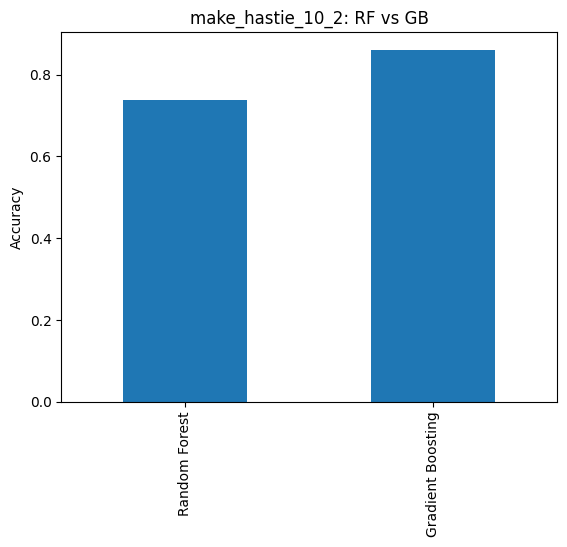

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_hastie_10_2
# from sklearn.model_selection import train_test_split
# from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
# from sklearn.metrics import accuracy_score

X, y = make_hastie_10_2(n_samples=5000, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = accuracy_score(y_test, model.predict(X_test))
print(results)
pd.Series(results).plot(kind='bar', title='make_hastie_10_2: RF vs GB')
plt.ylabel('Accuracy')
plt.show()


## Подбор гиперпараметров (GridSearchCV)

Вместо ручного перебора параметров используем **GridSearchCV**: по сетке вариантов выбираются те, при которых кросс-валидационная точность максимальна. Ниже — пример для Random Forest и для Gradient Boosting на тех же данных (Hastie 10-2).

In [ ]:
# Данные уже загружены выше (X_train, y_train из make_hastie_10_2)
# Если запускаете ячейку отдельно — выполните предыдущую ячейку «Сравнение моделей»
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Random Forest: сетка по n_estimators и max_depth
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
}
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1, verbose=0
)
grid_rf.fit(X_train, y_train)
print("Random Forest — лучшие параметры:", grid_rf.best_params_)
print("Random Forest — лучший cv-score:", f"{grid_rf.best_score_:.3f}")
print("Random Forest — accuracy на тесте:",
      f"{accuracy_score(y_test, grid_rf.predict(X_test)):.3f}")

print()

# Gradient Boosting: сетка по learning_rate, n_estimators, max_depth

Random Forest — лучшие параметры: {'max_depth': 7, 'n_estimators': 100}
Random Forest — лучший cv-score: 0.791
Random Forest — accuracy на тесте: 0.782



## Визуализация дерева решений

Попробуйте изменить `max_depth` и визуализировать дерево, чтобы понять, как оно принимает решения.


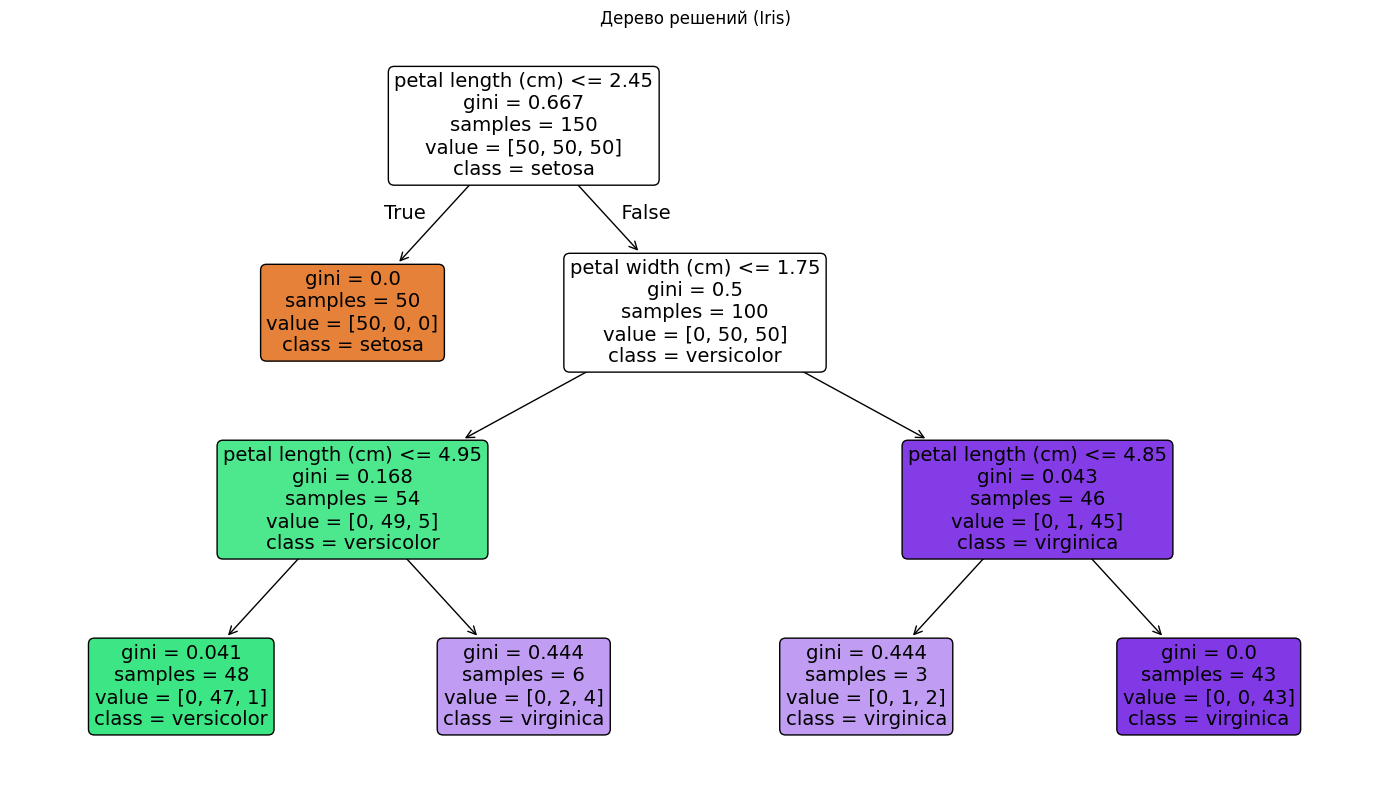

In [ ]:
from sklearn.tree import plot_tree

iris = load_iris()
# попробуйте 2,4,5
tree_viz = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_viz.fit(iris.data, iris.target)

plt.figure(figsize=(14, 8))
plot_tree(tree_viz,
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          filled=True, rounded=True)
plt.title("Дерево решений (Iris)")
plt.tight_layout()
plt.show()

## Свой ансамбль деревьев

Создайте **кастомный ансамбль**: обучите несколько деревьев разной глубины и усредните их предсказания вручную.


In [ ]:
# Ансамбль: деревья разной глубины + бутстрэп
# (разные подвыборки для разнообразия)
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

n_train = len(X_train)
depths = [2, 4, 6]  # можно изменить набор глубин
models_list = [DecisionTreeClassifier(max_depth=d, random_state=42 + i) for i, d in enumerate(depths)]

# Каждое дерево на своей бутстрэп-подвыборке (как в Bagging):
# ансамбль получает разнообразие
np.random.seed(42)
for i, tree in enumerate(models_list):
    idx = np.random.choice(n_train, size=n_train, replace=True)
    tree.fit(X_train[idx], y_train[idx])

# Усреднение предсказаний (вероятностей)
preds = np.array([tree.predict_proba(X_test) for tree in models_list])
mean_proba = np.mean(preds, axis=0)
final_pred = np.argmax(mean_proba, axis=1)

print("Accuracy кастомного ансамбля:", accuracy_score(y_test, final_pred))
# Сравнение с одним деревом (глубина 6, обучено на всех данных):
single = DecisionTreeClassifier(max_depth=6, random_state=42)
single.fit(X_train, y_train)
print("Accuracy одного дерева (depth=6):",
      accuracy_score(y_test, single.predict(X_test)))

Accuracy кастомного ансамбля: 0.9333333333333333
Accuracy одного дерева (depth=6): 0.92


## Мини-бустинг вручную

Реализуйте 2 итерации бустинга вручную:

1. Начните с `y_pred = np.zeros_like(y_train, dtype=float)`  
2. На каждой итерации обучайте дерево на остатках `(y_train - y_pred)`  
3. Обновляйте предсказания  
4. Сравните ошибки после каждой итерации


In [ ]:
# Мини-бустинг: 2 итерации на остатках (дерево регрессии предсказывает остаток)
import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor  # на остатках нужна регрессия!
from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=300, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
y_train = y_train.astype(float)
eta = 0.5  # шаг (learning rate)

y_pred = np.zeros_like(y_train, dtype=float)
trees = []

for step in range(2):
    residuals = y_train - y_pred
    tree = DecisionTreeRegressor(max_depth=2, random_state=42 + step)
    tree.fit(X_train, residuals)
    trees.append(tree)
    pred_step = tree.predict(X_train)  # регрессор возвращает непрерывные значения
    y_pred += eta * pred_step
    mse = np.mean((y_train - y_pred) ** 2)
    print(f"Итерация {step + 1}: MSE на train = {mse:.4f}")

# Финальное предсказание: сумма -> порог 0.5 для класса 0/1
y_test_sum = np.sum([eta * t.predict(X_test) for t in trees], axis=0)
y_test_pred = (y_test_sum > 0.5).astype(int)
print("Accuracy на тесте:", accuracy_score(y_test, y_test_pred))

Итерация 1: MSE на train = 0.1895
Итерация 2: MSE на train = 0.1049
Accuracy на тесте: 0.9066666666666666


# Если все успел: Супер-ансамбль и анализ ошибок

**Цель:** объединить Random Forest и Gradient Boosting в один ансамбль и проанализировать ошибки модели.

Создайте два классификатора на одном датасете (например, `make_moons` или `make_hastie_10_2`):

- Random Forest (`n_estimators=200`, `max_depth=5`)  
- Gradient Boosting (`n_estimators=200`, `learning_rate=0.1`)  

Объедините вероятности предсказаний двух моделей и сделайте финальное предсказание через [argmax](https://numpy.org/doc/2.2/reference/generated/numpy.argmax.html).

```python
# Пример подсказки
rf_probs = rf.predict_proba(X_test)
gb_probs = gb.predict_proba(X_test)
final_pred = np.argmax((rf_probs + gb_probs) / 2, axis=1)